In [1]:
# ======================================================
# Import Libraries
# ======================================================

import warnings
warnings.filterwarnings("ignore")

import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format","{:.6f}".format)

plt.style.use("ggplot")
sns.set_theme(style="darkgrid")

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# ======================================================
# Load Raw Dataset
# ======================================================

prices = pd.read_csv(
    "data/raw/raw_stock_prices.csv",
    index_col=0,
    parse_dates=True
)

benchmark = pd.read_csv(
    "data/raw/benchmark.csv",
    index_col=0,
    parse_dates=True
)

print("Stock Dataset Shape :", prices.shape)
print("Benchmark Shape :", benchmark.shape)

Stock Dataset Shape : (4170, 50)
Benchmark Shape : (4172, 5)


In [3]:
# ======================================================
# Preview Dataset
# ======================================================

display(prices.head())

display(prices.tail())

,AAPL,ABBV,ABT,ACN,ADBE,AMD,AMGN,AMZN,BAC,BLK,CAT,CRM,CSCO,CVX,DHR,GE,GOOGL,GS,HD,HON,IBM,INTC,JNJ,JPM,KO,LIN,LOW,MA,MCD,META,MRK,MS,MSFT,NFLX,NKE,NVDA,ORCL,PEP,PG,PM,QCOM,RTX,T,TSLA,TXN,UNH,UPS,V,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2010-01-04,6.406480,NaN,18.078800,30.856331,37.090000,9.700000,38.748535,6.695000,12.038228,156.575027,39.051937,18.386896,15.830378,40.890919,15.095536,53.458145,15.546578,129.387405,19.297071,26.546715,71.938805,13.519425,39.974812,28.152386,17.205250,59.821850,17.026024,23.502701,40.060699,NaN,20.314680,21.508480,23.027504,0.764000,13.062009,0.423290,19.878212,37.234718,37.580547,22.944681,31.051466,30.674999,6.585601,NaN,16.852434,24.269079,32.952579,19.564676,12.909191,37.377274
2010-01-05,6.417557,NaN,17.932741,31.047039,37.700001,9.710000,38.412888,6.734500,12.429532,157.250992,39.518829,18.308262,15.759848,41.180561,15.077461,53.734947,15.478117,131.674973,19.438416,26.599337,71.069809,13.512958,39.511292,28.697680,16.997128,58.707020,16.849590,23.433161,39.754406,NaN,20.397018,22.294781,23.034946,0.735857,13.113979,0.429471,19.854218,37.684643,37.592850,22.744751,31.798971,30.216772,6.553343,NaN,16.755251,24.230591,33.009216,19.340479,12.780644,37.523228
2010-01-06,6.315476,NaN,18.032322,31.377081,37.619999,9.570000,38.124214,6.612500,12.575309,154.008942,39.638882,18.276312,15.657268,41.185730,15.105583,53.458145,15.087934,130.269485,19.371111,26.599337,70.608147,13.467624,39.832664,28.855362,16.991095,59.227787,16.893711,23.399281,39.212009,NaN,20.671461,22.580065,22.893583,0.761714,13.034028,0.432219,19.566235,37.307682,37.414547,22.744751,31.488070,30.058334,6.488967,NaN,16.632149,24.469208,32.765671,19.080770,12.752076,37.847534
2010-01-07,6.303801,NaN,18.181707,31.347752,36.889999,9.470000,37.775131,6.500000,12.989630,155.702164,39.798965,18.195217,15.727795,41.030575,15.230124,56.226227,14.736692,132.818588,19.599957,27.112516,70.363731,13.338137,39.548367,29.426962,16.948856,59.381802,17.378893,23.246370,39.499153,NaN,20.704391,22.907118,22.655495,0.748571,13.161943,0.423748,19.502243,37.070549,37.211639,23.028360,32.400963,30.186798,6.416109,NaN,16.683985,25.408251,32.516449,19.258343,12.759222,37.728611
2010-01-08,6.345710,NaN,18.274662,31.223068,36.689999,9.430000,38.110790,6.676000,12.874540,156.798187,40.245850,18.222250,15.811138,41.102985,15.443043,57.437237,14.933151,130.306793,19.505732,27.711210,71.069809,13.487058,39.684334,29.354683,16.635166,59.770519,17.342148,23.254606,39.460884,NaN,20.693422,22.440901,22.811747,0.761429,13.135966,0.424664,19.742218,36.948948,37.162445,22.902828,32.725090,30.246746,6.369104,NaN,17.066256,25.169643,34.079678,19.311613,12.694949,37.577274


,AAPL,ABBV,ABT,ACN,ADBE,AMD,AMGN,AMZN,BAC,BLK,CAT,CRM,CSCO,CVX,DHR,GE,GOOGL,GS,HD,HON,IBM,INTC,JNJ,JPM,KO,LIN,LOW,MA,MCD,META,MRK,MS,MSFT,NFLX,NKE,NVDA,ORCL,PEP,PG,PM,QCOM,RTX,T,TSLA,TXN,UNH,UPS,V,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-07-28,340.079987,263.200012,107.269997,164.660004,249.179993,454.619995,393.100006,230.860001,62.619999,1097.550049,840.849976,181.500000,115.580002,187.580002,199.050003,363.589996,333.709991,1033.339966,344.470001,247.050003,227.550003,86.300003,266.730011,357.309998,88.269997,511.179993,218.240005,562.750000,273.019989,593.409973,131.820007,210.421677,393.350006,72.389999,43.049999,197.009995,119.959999,142.860001,148.880005,200.169998,162.880005,218.580002,24.660000,307.440002,275.658600,428.790009,105.529999,366.589996,113.099998,153.039993
2026-07-29,338.190002,263.299988,108.000000,173.169998,263.429993,429.559998,387.640015,226.649994,61.070000,1079.189941,782.710022,188.380005,112.480003,191.860001,196.490005,350.630005,336.709991,980.750000,338.269989,241.119995,226.440002,81.879997,265.529999,344.709991,89.080002,511.170013,215.679993,563.320007,271.519989,585.609985,130.360001,202.017944,390.540009,73.629997,43.220001,190.009995,117.739998,143.500000,146.100006,198.440002,155.679993,215.250000,23.940001,298.320007,269.917999,420.570007,104.559998,368.730011,114.220001,156.750000
2026-07-30,333.429993,257.410004,105.610001,163.289993,247.899994,485.390015,387.640015,235.500000,61.730000,1098.369995,809.140015,180.710007,113.559998,192.309998,196.169998,355.040009,333.660004,1024.859985,333.350006,241.910004,221.740005,91.129997,255.820007,350.850006,88.489998,508.640015,210.080002,577.349976,268.440002,539.030029,129.789993,208.910004,451.100006,73.169998,42.290001,195.039993,127.559998,140.199997,143.960007,192.000000,151.600006,214.380005,23.209999,308.850006,277.339996,421.470001,105.269997,366.269989,111.099998,156.970001
2026-07-31,308.910004,250.940002,105.699997,165.919998,250.410004,476.149994,385.160004,271.579987,61.950001,1090.390015,814.809998,184.020004,115.989998,196.830002,194.979996,360.070007,356.130005,1018.380005,331.959991,243.050003,223.649994,90.199997,256.350006,351.790009,87.589996,478.380005,207.809998,573.099976,270.640015,556.710022,130.199997,210.419998,464.720001,71.709999,41.709999,200.750000,129.869995,139.559998,144.490005,190.820007,147.610001,215.220001,23.250000,311.209991,275.739990,414.399994,104.220001,366.130005,111.199997,155.440002
2026-08-03,303.420013,245.100006,107.120003,165.759995,251.339996,484.640015,378.869995,284.019989,62.480000,1126.630005,830.030029,185.949997,115.860001,193.179993,197.500000,368.929993,373.510010,1027.060059,340.019989,246.770004,226.309998,91.000000,254.410004,352.640015,86.860001,480.459991,212.059998,570.969971,265.230011,590.239990,127.769997,211.229996,487.649994,73.330002,42.639999,206.639999,141.850006,139.630005,144.970001,187.410004,151.570007,216.649994,23.590000,322.079987,269.040009,415.359985,106.870003,365.670013,110.709999,155.059998


In [4]:
# ======================================================
# Dataset Information
# ======================================================

prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4170 entries, 2010-01-04 to 2026-08-03
Data columns (total 50 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    4170 non-null   float64
 1   ABBV    3416 non-null   float64
 2   ABT     4170 non-null   float64
 3   ACN     4170 non-null   float64
 4   ADBE    4170 non-null   float64
 5   AMD     4170 non-null   float64
 6   AMGN    4170 non-null   float64
 7   AMZN    4170 non-null   float64
 8   BAC     4170 non-null   float64
 9   BLK     4170 non-null   float64
 10  CAT     4170 non-null   float64
 11  CRM     4170 non-null   float64
 12  CSCO    4170 non-null   float64
 13  CVX     4170 non-null   float64
 14  DHR     4170 non-null   float64
 15  GE      4170 non-null   float64
 16  GOOGL   4170 non-null   float64
 17  GS      4170 non-null   float64
 18  HD      4170 non-null   float64
 19  HON     4170 non-null   float64
 20  IBM     4170 non-null   float64
 21  INTC    4170 non-nu

In [5]:
# ======================================================
# Descriptive Statistics
# ======================================================

prices.describe().T

,count,mean,std,min,25%,50%,75%,max
AAPL,4170.000000,84.484625,82.652071,5.749098,18.689429,40.594473,148.339855,340.079987
ABBV,3416.000000,90.772927,58.706037,19.596098,41.603530,68.107410,132.535473,263.299988
ABT,4170.000000,62.883305,37.016111,15.464270,30.220185,52.279186,99.762514,135.810669
ACN,4170.000000,156.607085,102.021038,26.961582,64.049011,134.719604,255.653275,386.351440
ADBE,4170.000000,237.100631,189.143459,22.690001,61.402499,218.215004,383.972496,688.369995
AMD,4170.000000,58.162456,81.919367,1.620000,5.300000,13.980000,94.470001,580.909973
AMGN,4170.000000,155.025466,86.627481,32.404591,82.338926,141.794525,211.590939,393.100006
AMZN,4170.000000,86.016713,73.807138,5.430500,15.714375,75.864750,152.856503,284.019989
BAC,4170.000000,22.802821,13.076250,3.858367,11.860058,21.349064,31.281012,62.619999
BLK,4170.000000,446.700581,288.148224,92.498367,223.565479,359.155670,649.540359,1183.470093


In [6]:
# ======================================================
# Missing Values
# ======================================================

missing = prices.isnull().sum()

missing = missing[missing>0]

missing.sort_values(ascending=False)

ABBV    754
META    599
TSLA    122
dtype: int64

In [7]:
# ======================================================
# Missing Value Percentage
# ======================================================

missing_percent = (
    prices.isnull().mean()*100
).sort_values(ascending=False)

missing_percent[missing_percent>0]

ABBV   18.081535
META   14.364508
TSLA    2.925659
dtype: float64

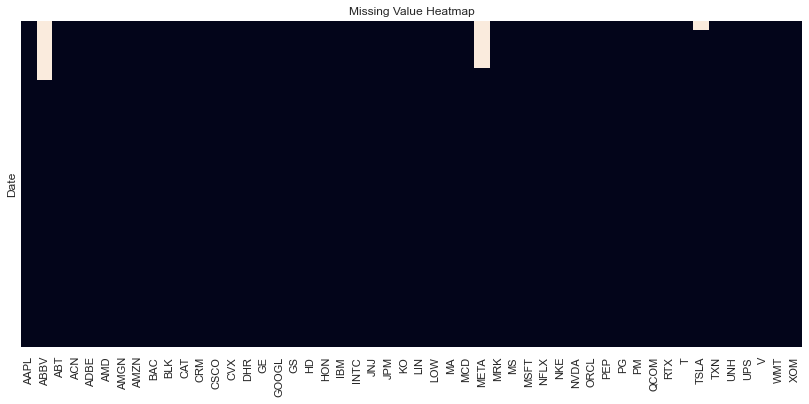

In [8]:
plt.figure(figsize=(14,6))

sns.heatmap(
    prices.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Value Heatmap")

plt.show()

In [9]:
print("""
Stocks with missing values:

ABBV -> IPO in 2013

META -> IPO in 2012

TSLA -> IPO in 2010

These are NOT bad data.

They simply did not exist before those dates.
""")


Stocks with missing values:

ABBV -> IPO in 2013

META -> IPO in 2012

TSLA -> IPO in 2010

These are NOT bad data.

They simply did not exist before those dates.



In [10]:
duplicates = prices.duplicated().sum()

print("Duplicate Rows :",duplicates)

Duplicate Rows : 0


In [11]:
print("Start Date :",prices.index.min())

print("End Date :",prices.index.max())

print("Total Days :",len(prices))

Start Date : 2010-01-04 00:00:00
End Date : 2026-08-03 00:00:00
Total Days : 4170


In [12]:
prices = prices.dropna(how="all")

prices.shape

(4170, 50)

In [13]:
prices = prices.ffill()

In [14]:
prices.isnull().sum().sort_values(ascending=False).head(10)

ABBV    754
META    599
TSLA    122
AAPL      0
ORCL      0
MA        0
MCD       0
MRK       0
MS        0
MSFT      0
dtype: int64

In [15]:
daily_returns = prices.pct_change()

daily_returns.head()

,AAPL,ABBV,ABT,ACN,ADBE,AMD,AMGN,AMZN,BAC,BLK,CAT,CRM,CSCO,CVX,DHR,GE,GOOGL,GS,HD,HON,IBM,INTC,JNJ,JPM,KO,LIN,LOW,MA,MCD,META,MRK,MS,MSFT,NFLX,NKE,NVDA,ORCL,PEP,PG,PM,QCOM,RTX,T,TSLA,TXN,UNH,UPS,V,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.001729,NaN,-0.008079,0.006181,0.016446,0.001031,-0.008662,0.005900,0.032505,0.004317,0.011956,-0.004277,-0.004455,0.007083,-0.001197,0.005178,-0.004404,0.017680,0.007325,0.001982,-0.012080,-0.000478,-0.011595,0.019369,-0.012096,-0.018636,-0.010363,-0.002959,-0.007646,NaN,0.004053,0.036558,0.000323,-0.036836,0.003979,0.014603,-0.001207,0.012083,0.000327,-0.008714,0.024073,-0.014938,-0.004898,NaN,-0.005767,-0.001586,0.001719,-0.011459,-0.009958,0.003905
2010-01-06,-0.015906,NaN,0.005553,0.010630,-0.002122,-0.014418,-0.007515,-0.018116,0.011728,-0.020617,0.003038,-0.001745,-0.006509,0.000126,0.001865,-0.005151,-0.025209,-0.010674,-0.003462,0.000000,-0.006496,-0.003355,0.008134,0.005495,-0.000355,0.008871,0.002619,-0.001446,-0.013644,NaN,0.013455,0.012796,-0.006137,0.035139,-0.006097,0.006397,-0.014505,-0.010003,-0.004743,0.000000,-0.009777,-0.005243,-0.009823,NaN,-0.007347,0.009848,-0.007378,-0.013428,-0.002235,0.008643
2010-01-07,-0.001849,NaN,0.008284,-0.000935,-0.019405,-0.010449,-0.009156,-0.017013,0.032947,0.010994,0.004039,-0.004437,0.004504,-0.003767,0.008245,0.051780,-0.023280,0.019568,0.011814,0.019293,-0.003462,-0.009615,-0.007137,0.019809,-0.002486,0.002600,0.028720,-0.006535,0.007323,NaN,0.001593,0.014484,-0.010400,-0.017255,0.009814,-0.019597,-0.003271,-0.006356,-0.005423,0.012469,0.028992,0.004274,-0.011228,NaN,0.003117,0.038377,-0.007606,0.009306,0.000560,-0.003142
2010-01-08,0.006648,NaN,0.005113,-0.003977,-0.005422,-0.004224,0.008886,0.027077,-0.008860,0.007039,0.011229,0.001486,0.005299,0.001765,0.013980,0.021538,0.013331,-0.018911,-0.004807,0.022082,0.010035,0.011165,0.003438,-0.002456,-0.018508,0.006546,-0.002114,0.000354,-0.000969,NaN,-0.000530,-0.020352,0.006897,0.017177,-0.001974,0.002161,0.012305,-0.003280,-0.001322,-0.005451,0.010004,0.001986,-0.007326,NaN,0.022912,-0.009391,0.048075,0.002766,-0.005037,-0.004011


In [16]:
log_returns = np.log(prices/prices.shift(1))

log_returns.head()

,AAPL,ABBV,ABT,ACN,ADBE,AMD,AMGN,AMZN,BAC,BLK,CAT,CRM,CSCO,CVX,DHR,GE,GOOGL,GS,HD,HON,IBM,INTC,JNJ,JPM,KO,LIN,LOW,MA,MCD,META,MRK,MS,MSFT,NFLX,NKE,NVDA,ORCL,PEP,PG,PM,QCOM,RTX,T,TSLA,TXN,UNH,UPS,V,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.001727,NaN,-0.008112,0.006161,0.016313,0.001030,-0.008700,0.005883,0.031988,0.004308,0.011885,-0.004286,-0.004465,0.007058,-0.001198,0.005165,-0.004413,0.017526,0.007298,0.001980,-0.012153,-0.000479,-0.011663,0.019184,-0.012170,-0.018812,-0.010417,-0.002963,-0.007675,NaN,0.004045,0.035905,0.000323,-0.037532,0.003971,0.014497,-0.001208,0.012011,0.000327,-0.008752,0.023788,-0.015051,-0.004910,NaN,-0.005783,-0.001587,0.001717,-0.011525,-0.010008,0.003897
2010-01-06,-0.016034,NaN,0.005538,0.010574,-0.002124,-0.014523,-0.007543,-0.018282,0.011660,-0.020833,0.003033,-0.001747,-0.006530,0.000126,0.001863,-0.005165,-0.025532,-0.010731,-0.003468,0.000000,-0.006517,-0.003360,0.008101,0.005480,-0.000355,0.008831,0.002615,-0.001447,-0.013738,NaN,0.013365,0.012715,-0.006156,0.034535,-0.006115,0.006376,-0.014611,-0.010053,-0.004754,0.000000,-0.009825,-0.005257,-0.009872,NaN,-0.007374,0.009800,-0.007405,-0.013519,-0.002238,0.008606
2010-01-07,-0.001850,NaN,0.008250,-0.000935,-0.019595,-0.010504,-0.009199,-0.017160,0.032416,0.010934,0.004030,-0.004447,0.004494,-0.003774,0.008211,0.050484,-0.023555,0.019379,0.011745,0.019109,-0.003468,-0.009661,-0.007163,0.019615,-0.002489,0.002597,0.028315,-0.006556,0.007296,NaN,0.001592,0.014380,-0.010454,-0.017405,0.009766,-0.019792,-0.003276,-0.006376,-0.005438,0.012392,0.028579,0.004265,-0.011291,NaN,0.003112,0.037658,-0.007635,0.009263,0.000560,-0.003147
2010-01-08,0.006626,NaN,0.005100,-0.003985,-0.005436,-0.004233,0.008846,0.026717,-0.008900,0.007015,0.011166,0.001485,0.005285,0.001763,0.013883,0.021310,0.013243,-0.019093,-0.004819,0.021842,0.009985,0.011103,0.003432,-0.002459,-0.018681,0.006525,-0.002117,0.000354,-0.000969,NaN,-0.000530,-0.020562,0.006873,0.017031,-0.001976,0.002159,0.012230,-0.003286,-0.001323,-0.005466,0.009954,0.001984,-0.007353,NaN,0.022654,-0.009435,0.046955,0.002762,-0.005050,-0.004019


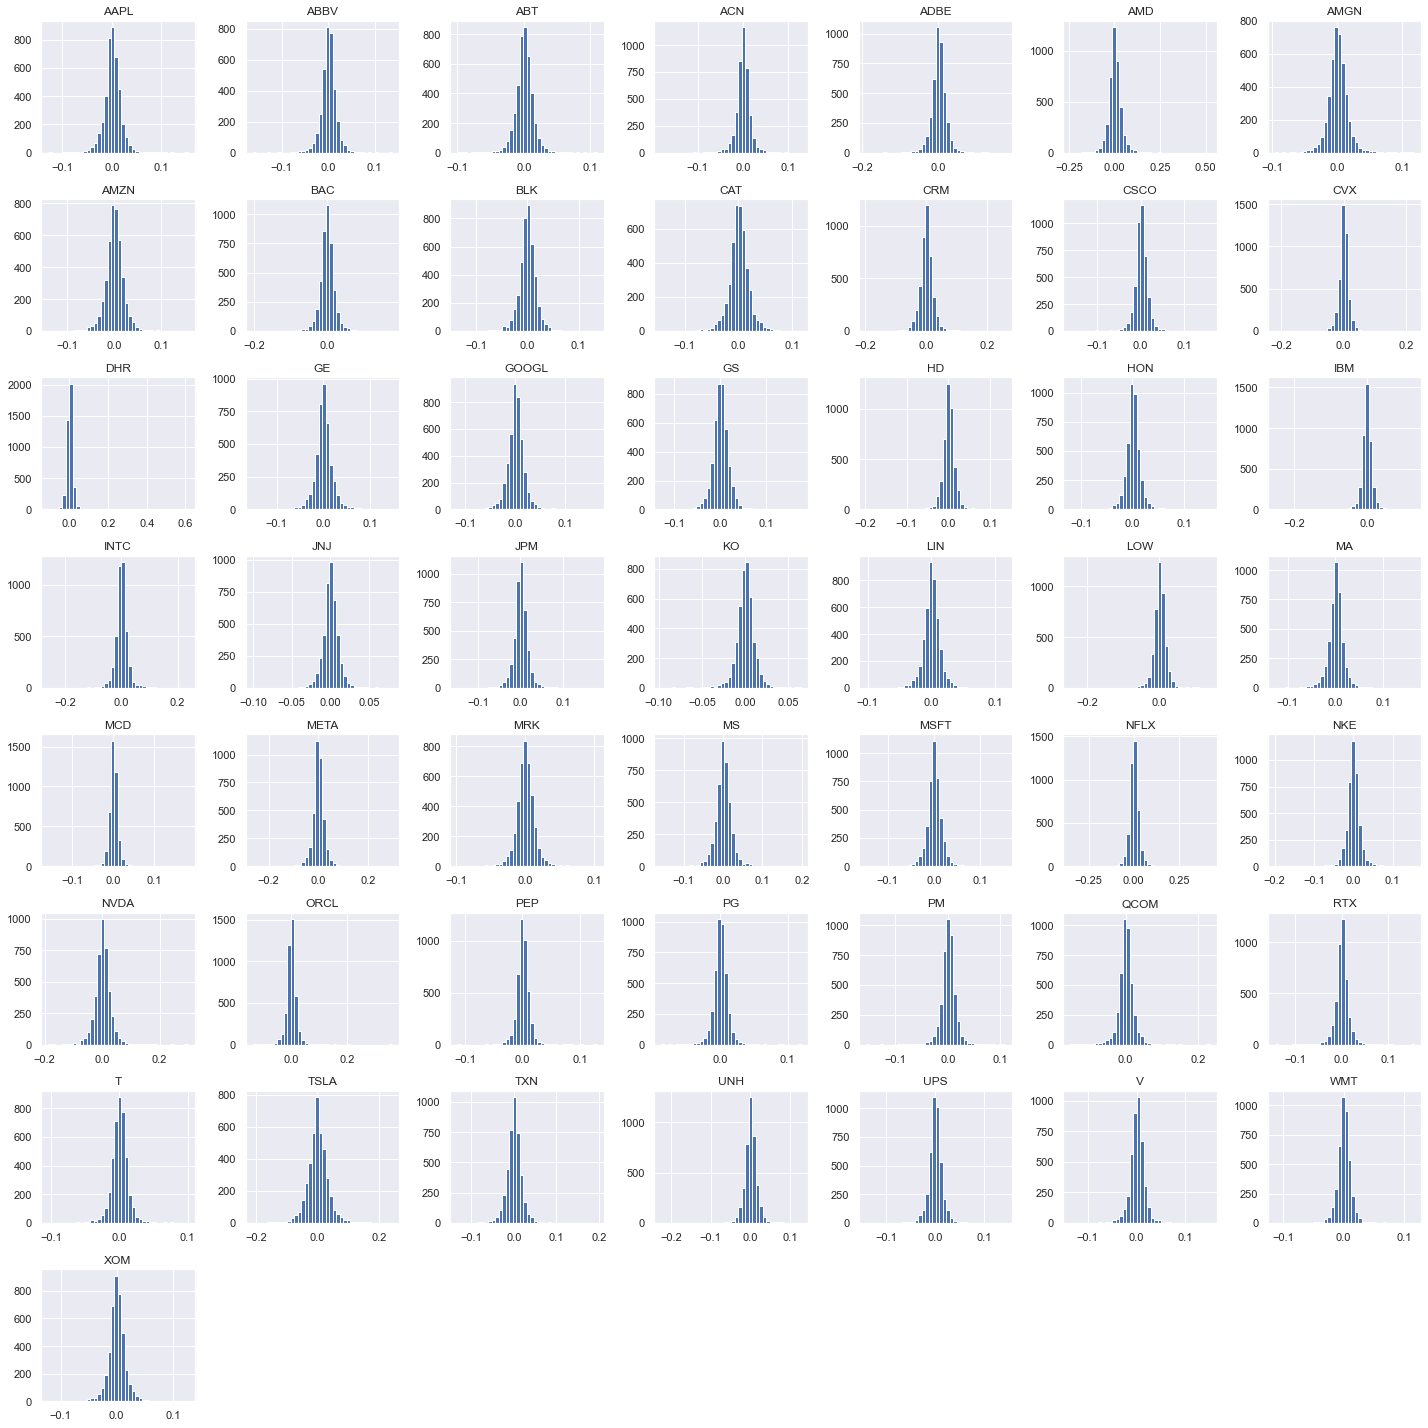

In [17]:
daily_returns.hist(
    figsize=(20,20),
    bins=40
)

plt.tight_layout()

plt.show()

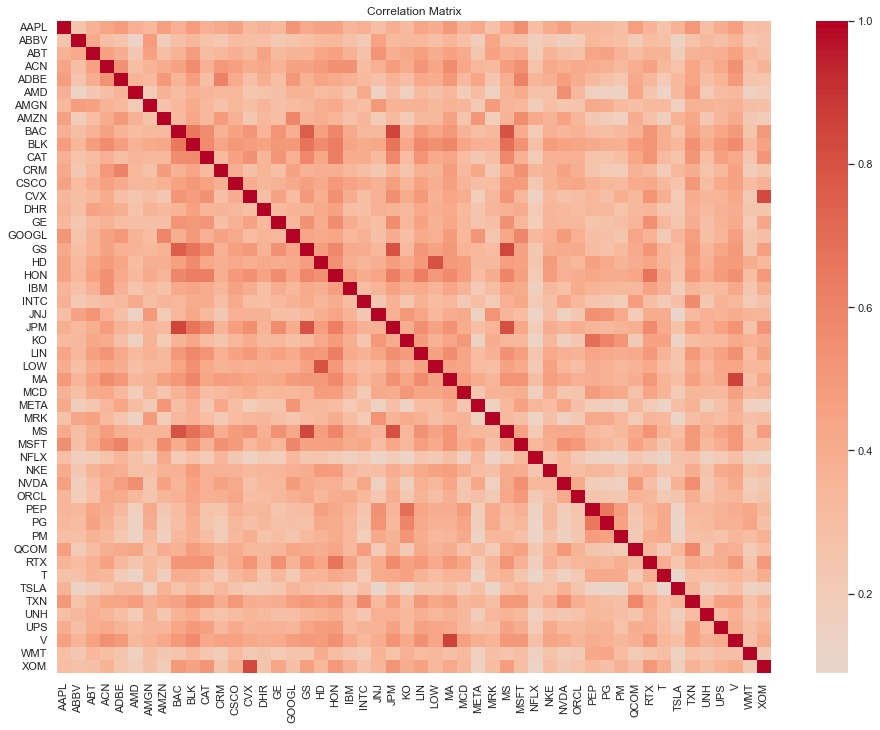

In [18]:
plt.figure(figsize=(16,12))

sns.heatmap(
    daily_returns.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.show()

In [19]:
prices.to_csv(
    "data/processed/clean_prices.csv"
)

daily_returns.to_csv(
    "data/processed/daily_returns.csv"
)

log_returns.to_csv(
    "data/processed/log_returns.csv"
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


In [20]:
print("="*50)
print("PHASE 2 COMPLETED")
print("="*50)

print("Files Generated")

print("✔ clean_prices.csv")
print("✔ daily_returns.csv")
print("✔ log_returns.csv")

print()

print("Ready for Phase 3 - Portfolio Construction")

PHASE 2 COMPLETED
Files Generated
✔ clean_prices.csv
✔ daily_returns.csv
✔ log_returns.csv

Ready for Phase 3 - Portfolio Construction
